# 06 — Future Electricity Demand Forecasting

## Project Overview

This notebook uses previously trained Random Forest models
to generate seven-day electricity demand forecasts for
New Zealand's five electricity regions.

### Forecasting Regions

- UNI — Upper North Island
- CNI — Central North Island
- LNI — Lower North Island
- USI — Upper South Island
- LSI — Lower South Island

### Forecasting Approach

Each regional model uses either 14 or 28 days of historical
electricity demand to predict the following seven days.

The models generate 336 half-hourly predictions per region.

### Objectives

1. Load the saved regional forecasting models.
2. Retrieve the latest available electricity demand data.
3. Verify that historical observations are consecutive.
4. Generate seven-day forecasts for all five regions.
5. Visualise predicted electricity demand.
6. Export forecasts for further analysis.

### Model Performance

During held-out testing, the models achieved MAPE values
ranging from 3.16% to 7.43%.

All five models outperformed the seasonal naïve baseline.

## 1. Loading the Regional Forecasting Models

### Objective

Load the five previously trained Random Forest models and
their saved configurations.

Each model has a region-specific historical lookback window
and generates 336 half-hourly electricity demand predictions.

Loading the saved models eliminates the need for retraining
when generating new forecasts.

In [1]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path

# Project directories
project_dir = Path.cwd().parent
models_dir = project_dir / "models"
data_dir = project_dir / "data"

# Load model configurations
configurations = joblib.load(
    models_dir / "regional_model_config.pkl"
)

# Regional identifiers
regions = ["UNI", "CNI", "LNI", "USI", "LSI"]

# Load trained models
models = {}

for region in regions:

    models[region] = joblib.load(
        models_dir / f"random_forest_{region}_7day.pkl"
    )

    config = configurations[region]

    print(
        f"{region} | "
        f"Lookback: {config['lookback_days']} days | "
        f"Forecast: {config['forecast_days']} days | "
        f"Status: LOADED"
    )

print("\nAll five regional models loaded successfully.")

UNI | Lookback: 28 days | Forecast: 7 days | Status: LOADED
CNI | Lookback: 28 days | Forecast: 7 days | Status: LOADED
LNI | Lookback: 14 days | Forecast: 7 days | Status: LOADED
USI | Lookback: 28 days | Forecast: 7 days | Status: LOADED
LSI | Lookback: 14 days | Forecast: 7 days | Status: LOADED

All five regional models loaded successfully.


## 2. Historical Data Preparation

### Objective

Load the historical electricity demand dataset and verify
that sufficient observations are available for forecasting.

Each regional model requires:

- 14 or 28 days of historical electricity demand.
- 48 half-hourly observations per day.
- Consecutive calendar dates without missing days.
- No missing electricity demand values.

### Data Validation

We will identify the latest available observation for each
region and check whether the required historical window
contains complete, consecutive days.

Only validated historical data will be used to generate
future electricity demand forecasts.

In [2]:
# Load historical electricity demand data
data_path = data_dir / "electricity_demand_features.csv"

df = pd.read_csv(
    data_path,
    parse_dates=["Period start"]
)

print("Dataset shape:", df.shape)

# Prepare complete daily demand profiles
regional_profiles = {}

for region in regions:

    region_data = df[
        df["Region ID"] == region
    ].copy()

    region_data["Date"] = (
        region_data["Period start"].dt.normalize()
    )

    region_data["Period"] = (
        region_data["Period start"].dt.hour * 2
        + region_data["Period start"].dt.minute // 30
    )

    # Convert half-hourly observations into daily profiles
    profiles = region_data.pivot_table(
        index="Date",
        columns="Period",
        values="Demand (GWh)",
        aggfunc="mean"
    )

    profiles = profiles.reindex(columns=range(48))

    # Retain only complete days
    profiles = profiles.dropna().sort_index()

    regional_profiles[region] = profiles

    # Check latest required historical window
    lookback = configurations[region]["lookback_days"]

    historical = profiles.iloc[-lookback:]

    expected_dates = pd.date_range(
        start=historical.index[0],
        periods=lookback,
        freq="D"
    )

    consecutive = historical.index.equals(expected_dates)

    print(f"\nRegion: {region}")
    print(f"Latest complete day: {profiles.index[-1].date()}")
    print(f"Required lookback: {lookback} days")
    print(f"Available complete days: {len(profiles)}")
    print(f"Consecutive historical days: {consecutive}")

    if not consecutive:
        print("WARNING: Historical window contains missing days.")

Dataset shape: (172597, 13)

Region: UNI
Latest complete day: 2026-10-31
Required lookback: 28 days
Available complete days: 692
Consecutive historical days: False

Region: CNI
Latest complete day: 2026-10-31
Required lookback: 28 days
Available complete days: 694
Consecutive historical days: False

Region: LNI
Latest complete day: 2026-10-31
Required lookback: 14 days
Available complete days: 689
Consecutive historical days: True

Region: USI
Latest complete day: 2026-10-31
Required lookback: 28 days
Available complete days: 688
Consecutive historical days: False

Region: LSI
Latest complete day: 2026-10-31
Required lookback: 14 days
Available complete days: 677
Consecutive historical days: True


## 2.1 Identifying Missing Historical Dates

### Objective

Identify missing calendar dates within each region's required
historical lookback window.

Incomplete days were excluded during data preparation.
Consequently, the latest available daily profiles may contain
gaps in their calendar dates.

Before generating forecasts, we must identify these gaps
and determine whether a valid consecutive historical window
is available.


In [3]:
for region in regions:

    profiles = regional_profiles[region]
    lookback = configurations[region]["lookback_days"]

    # Latest complete observation
    latest_date = profiles.index.max()

    # Required calendar window
    expected_dates = pd.date_range(
        end=latest_date,
        periods=lookback,
        freq="D"
    )

    # Identify missing days
    missing_dates = expected_dates.difference(
        profiles.index
    )

    print(f"\n{region}")
    print(f"Required lookback: {lookback} days")
    print(f"Latest date: {latest_date.date()}")
    print(f"Missing days: {len(missing_dates)}")

    if len(missing_dates) > 0:
        print(
            "Missing dates:",
            [date.strftime("%Y-%m-%d") for date in missing_dates]
        )
    else:
        print("Status: READY")


UNI
Required lookback: 28 days
Latest date: 2026-10-31
Missing days: 1
Missing dates: ['2026-10-04']

CNI
Required lookback: 28 days
Latest date: 2026-10-31
Missing days: 1
Missing dates: ['2026-10-04']

LNI
Required lookback: 14 days
Latest date: 2026-10-31
Missing days: 0
Status: READY

USI
Required lookback: 28 days
Latest date: 2026-10-31
Missing days: 1
Missing dates: ['2026-10-04']

LSI
Required lookback: 14 days
Latest date: 2026-10-31
Missing days: 0
Status: READY


## 2.2 Investigating Daylight Saving Time

New Zealand daylight saving time began on 4 October 2026.

On this date, clocks advanced from 2:00 AM to 3:00 AM,
resulting in a 23-hour day.

This may explain why some regional daily demand profiles
contain fewer than the expected 48 half-hourly observations.

We will inspect the original dataset before applying
any adjustments.

In [4]:
# Inspect observations on 4 October 2026

dst_date = pd.Timestamp("2026-10-04")

for region in regions:

    region_data = df[
        (df["Region ID"] == region)
        & (
            df["Period start"].dt.normalize()
            == dst_date
        )
    ].sort_values("Period start")

    print(f"\n{region}")
    print(f"Observations: {len(region_data)}")

    print(
        region_data[
            ["Period start", "Demand (GWh)"]
        ].head(10).to_string(index=False)
    )


UNI
Observations: 46
       Period start  Demand (GWh)
2026-10-04 00:00:00         0.520
2026-10-04 00:30:00         0.497
2026-10-04 01:00:00         0.481
2026-10-04 01:30:00         0.466
2026-10-04 03:00:00         0.447
2026-10-04 03:30:00         0.449
2026-10-04 04:00:00         0.450
2026-10-04 04:30:00         0.437
2026-10-04 05:00:00         0.462
2026-10-04 05:30:00         0.472

CNI
Observations: 46
       Period start  Demand (GWh)
2026-10-04 00:00:00         0.389
2026-10-04 00:30:00         0.380
2026-10-04 01:00:00         0.373
2026-10-04 01:30:00         0.365
2026-10-04 03:00:00         0.357
2026-10-04 03:30:00         0.352
2026-10-04 04:00:00         0.353
2026-10-04 04:30:00         0.357
2026-10-04 05:00:00         0.375
2026-10-04 05:30:00         0.395

LNI
Observations: 46
       Period start  Demand (GWh)
2026-10-04 00:00:00         0.314
2026-10-04 00:30:00         0.303
2026-10-04 01:00:00         0.296
2026-10-04 01:30:00         0.287
2026-10-04 03:00

## 2.3 Handling Daylight Saving Time

### Problem

On 4 October 2026, New Zealand transitioned to daylight
saving time, resulting in a 23-hour day.

Consequently, each electricity region contains only
46 half-hourly observations instead of the usual 48.

The missing periods are 02:00 and 02:30.

### Method

To maintain compatibility with the trained Random Forest
models, we reconstruct the two missing periods using
linear interpolation.

The interpolation estimates values between the observed
01:30 and 03:00 electricity demand readings.

### Important Considerations

- The reconstructed values are synthetic, not actual demand.
- The original electricity dataset remains unchanged.
- The adjustment is applied only to forecasting inputs.
- This approach preserves the 48-period daily structure.
- Forecast accuracy around daylight saving transitions
  has not been independently validated.

### Objective

Prepare complete and consecutive historical demand profiles
for all five regions before generating seven-day forecasts.

In [5]:
# ============================================================
# HANDLE DAYLIGHT SAVING TIME
# ============================================================

dst_date = pd.Timestamp("2026-10-04")

forecast_profiles = {}

for region in regions:

    # Retrieve regional observations
    region_data = df[
        df["Region ID"] == region
    ].copy()

    region_data["Date"] = (
        region_data["Period start"].dt.normalize()
    )

    region_data["Period"] = (
        region_data["Period start"].dt.hour * 2
        + region_data["Period start"].dt.minute // 30
    )

    # Create daily demand profiles
    profiles = region_data.pivot_table(
        index="Date",
        columns="Period",
        values="Demand (GWh)",
        aggfunc="mean"
    )

    profiles = profiles.reindex(columns=range(48))

    # Interpolate only the two DST periods
    if dst_date in profiles.index:

        missing_periods = profiles.loc[
            dst_date, [4, 5]
        ]

        if (
            missing_periods.isna().all()
            and profiles.loc[dst_date].isna().sum() == 2
        ):

            profiles.loc[dst_date] = (
                profiles.loc[dst_date]
                .interpolate(method="linear")
            )

    # Keep complete daily profiles
    profiles = profiles.dropna().sort_index()

    forecast_profiles[region] = profiles

    # Verify required historical window
    lookback = configurations[region]["lookback_days"]

    historical = profiles.iloc[-lookback:]

    expected_dates = pd.date_range(
        end=historical.index[-1],
        periods=lookback,
        freq="D"
    )

    consecutive = historical.index.equals(expected_dates)

    print(
        f"{region} | "
        f"Lookback: {lookback} days | "
        f"Consecutive: {consecutive} | "
        f"Status: {'READY' if consecutive else 'CHECK'}"
    )

UNI | Lookback: 28 days | Consecutive: True | Status: READY
CNI | Lookback: 28 days | Consecutive: True | Status: READY
LNI | Lookback: 14 days | Consecutive: True | Status: READY
USI | Lookback: 28 days | Consecutive: True | Status: READY
LSI | Lookback: 14 days | Consecutive: True | Status: READY


## 3. Generating Seven-Day Regional Forecasts

### Objective

Generate seven-day electricity demand forecasts for all five
New Zealand electricity regions using the saved Random Forest models.

### Forecast Period

- Historical data ends: 31 October 2026
- Forecast begins: 1 November 2026
- Forecast ends: 7 November 2026
- Forecast resolution: 30 minutes
- Predictions per region: 336
- Total predictions: 1,680

### Method

Each model receives its required historical lookback window:

- UNI, CNI and USI: 28 days
- LNI and LSI: 14 days

The historical observations are flattened into a single input
vector before being passed to the corresponding regional model.

Predictions are expressed in gigawatt-hours (GWh) per
half-hourly period.

These forecasts are generated using historical data ending
31 October 2026 and are not live forecasts.

In [6]:
# ============================================================
# GENERATE SEVEN-DAY FORECASTS FOR ALL FIVE REGIONS
# ============================================================

all_forecasts = []

for region in regions:

    model = models[region]
    lookback = configurations[region]["lookback_days"]

    # Retrieve historical data
    profiles = forecast_profiles[region]

    historical = profiles.iloc[-lookback:]

    # Validate historical dates
    expected_dates = pd.date_range(
        end=historical.index[-1],
        periods=lookback,
        freq="D"
    )

    if not historical.index.equals(expected_dates):
        raise ValueError(
            f"{region}: Historical dates are not consecutive."
        )

    # Prepare model input
    X_new = historical.to_numpy().flatten().reshape(1, -1)

    # Generate predictions
    predictions = model.predict(X_new).flatten()

    # Create forecast timestamps
    forecast_start = historical.index[-1] + pd.Timedelta(days=1)

    forecast_dates = pd.date_range(
        start=forecast_start,
        periods=336,
        freq="30min"
    )

    # Store regional forecasts
    region_forecast = pd.DataFrame({
        "Period start": forecast_dates,
        "Region ID": region,
        "Predicted Demand (GWh)": predictions
    })

    all_forecasts.append(region_forecast)

    print(
        f"{region} | "
        f"Predictions: {len(predictions)} | "
        f"Mean demand: {predictions.mean():.3f} GWh"
    )

# Combine all regional forecasts
forecast_df = pd.concat(
    all_forecasts,
    ignore_index=True
)

print("\nForecast dataset shape:", forecast_df.shape)

display(forecast_df.head(10))

UNI | Predictions: 336 | Mean demand: 0.639 GWh
CNI | Predictions: 336 | Mean demand: 0.454 GWh
LNI | Predictions: 336 | Mean demand: 0.310 GWh
USI | Predictions: 336 | Mean demand: 0.357 GWh
LSI | Predictions: 336 | Mean demand: 0.552 GWh

Forecast dataset shape: (1680, 3)


,Period start,Region ID,Predicted Demand (GWh)
0,2026-11-01 00:00:00,UNI,0.512820
1,2026-11-01 00:30:00,UNI,0.494982
2,2026-11-01 01:00:00,UNI,0.479753
3,2026-11-01 01:30:00,UNI,0.469363
4,2026-11-01 02:00:00,UNI,0.464814
5,2026-11-01 02:30:00,UNI,0.457704
6,2026-11-01 03:00:00,UNI,0.451802
7,2026-11-01 03:30:00,UNI,0.447805
8,2026-11-01 04:00:00,UNI,0.446131
9,2026-11-01 04:30:00,UNI,0.449219


## 3.1 Visualising Seven-Day Electricity Demand Forecasts

### Objective

Visualise predicted electricity demand across New Zealand's
five electricity regions from 1–7 November 2026.

### Analysis

The visualisation will help identify:

- Daily electricity demand cycles.
- Differences in regional electricity consumption.
- Peak and off-peak demand periods.
- Changes in predicted demand throughout the week.

### Interpretation

Each regional forecast contains 336 half-hourly predictions.

Electricity demand is measured in gigawatt-hours (GWh)
per half-hourly period.

The forecasts represent model estimates rather than
observed electricity demand.

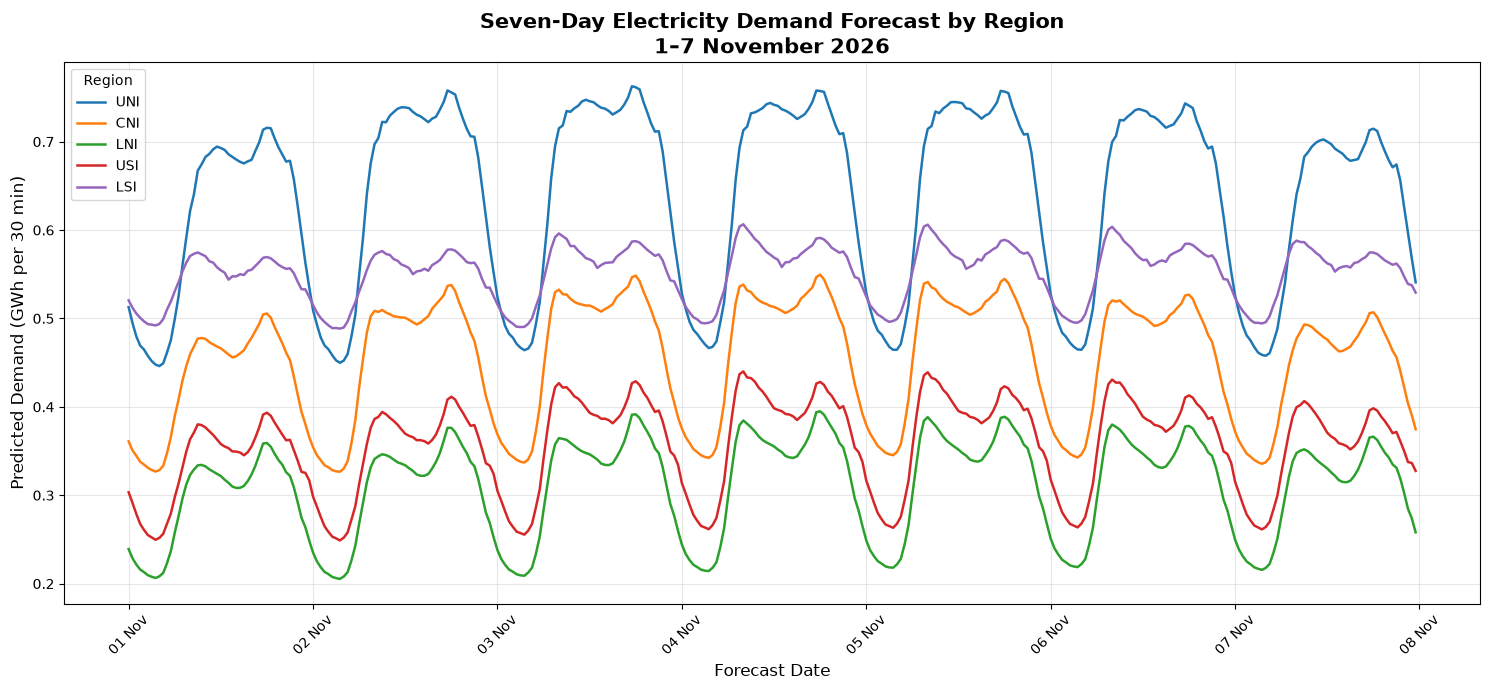

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create figure
fig, ax = plt.subplots(figsize=(15, 7))

# Plot each region
for region in regions:

    region_forecast = forecast_df[
        forecast_df["Region ID"] == region
    ]

    ax.plot(
        region_forecast["Period start"],
        region_forecast["Predicted Demand (GWh)"],
        label=region,
        linewidth=1.8
    )

# Chart formatting
ax.set_title(
    "Seven-Day Electricity Demand Forecast by Region\n"
    "1–7 November 2026",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Forecast Date", fontsize=12)
ax.set_ylabel("Predicted Demand (GWh per 30 min)", fontsize=12)

ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

ax.legend(title="Region")
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

# Save figure
figures_dir = project_dir / "figures"
figures_dir.mkdir(exist_ok=True)

plt.savefig(
    figures_dir / "seven_day_regional_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3.2 Interpretation of Regional Forecasts

### Forecast Overview

The five Random Forest models generated 1,680 half-hourly
electricity demand predictions for 1–7 November 2026.

All regions display recurring daily demand cycles, with
lower predicted consumption overnight and higher consumption
during daytime and evening periods.

### Regional Differences

**Upper North Island (UNI)**

UNI has the highest average predicted demand at 0.639 GWh
per half-hour. The forecast displays pronounced daily
fluctuations.

**Lower South Island (LSI)**

LSI has the second-highest average predicted demand at
0.552 GWh. Its forecast displays smaller relative
fluctuations throughout the day.

**Central North Island (CNI)**

CNI has an average predicted demand of 0.454 GWh,
with identifiable daily peaks and overnight reductions.

**Upper South Island (USI)**

USI has an average predicted demand of 0.357 GWh.
The model predicts recurring daily demand fluctuations.

**Lower North Island (LNI)**

LNI has the lowest average predicted demand at 0.310 GWh.

### Key Findings

1. All five regions display recognisable daily demand cycles.
2. UNI has the highest predicted electricity consumption.
3. Regional demand patterns differ in magnitude and variability.
4. The models produce smooth, continuous seven-day forecasts.

### Limitations

These predictions have not been compared with actual
electricity demand for 1–7 November 2026.

The forecasts are generated using historical observations
ending 31 October 2026.

The visual patterns should therefore be interpreted as
model predictions rather than confirmed demand outcomes.

In [8]:
# ============================================================
# EXPORT REGIONAL ELECTRICITY DEMAND FORECASTS
# ============================================================

# Create forecasts directory
forecasts_dir = project_dir / "forecasts"
forecasts_dir.mkdir(parents=True, exist_ok=True)

# Export predictions
output_path = (
    forecasts_dir /
    "regional_electricity_forecast_2026_11_01.csv"
)

forecast_df.to_csv(
    output_path,
    index=False
)

print("Forecast exported successfully.")
print(f"File: {output_path.name}")
print(f"Total predictions: {len(forecast_df):,}")
print(f"Regions: {forecast_df['Region ID'].nunique()}")
print(
    f"Forecast period: "
    f"{forecast_df['Period start'].min()} to "
    f"{forecast_df['Period start'].max()}"
)

Forecast exported successfully.
File: regional_electricity_forecast_2026_11_01.csv
Total predictions: 1,680
Regions: 5
Forecast period: 2026-11-01 00:00:00 to 2026-11-07 23:30:00


## 4. Regional and National Electricity Demand Analysis

### Objective

Aggregate the seven-day electricity demand forecasts to
estimate total electricity consumption across New Zealand.

### Methodology

Each prediction represents electricity consumption in GWh
during a 30-minute period.

Summing these predictions provides the total forecast
electricity consumption over seven days.

We will calculate:

- Total predicted electricity consumption by region.
- Each region's percentage contribution to national demand.
- Total predicted electricity consumption across New Zealand.
- Average daily national electricity consumption.

### Units

- GWh: Gigawatt-hours (energy).
- 1 GWh = 1,000 MWh.
- 1 GWh = 1,000,000 kWh.

Because the predictions already represent energy consumed
during each half-hour period, they can be summed directly
without multiplying by 0.5.

In [9]:
# ============================================================
# REGIONAL AND NATIONAL ELECTRICITY DEMAND
# ============================================================

# Calculate total predicted consumption by region
regional_totals = (
    forecast_df
    .groupby("Region ID")["Predicted Demand (GWh)"]
    .sum()
    .sort_values(ascending=False)
)

# Calculate national total
national_total = regional_totals.sum()

# Create summary table
demand_summary = pd.DataFrame({
    "Region": regional_totals.index,
    "Total Demand (GWh)": regional_totals.values
})

# Calculate regional percentage contributions
demand_summary["National Share (%)"] = (
    demand_summary["Total Demand (GWh)"]
    / national_total
    * 100
)

# Calculate average daily demand
demand_summary["Average Daily Demand (GWh)"] = (
    demand_summary["Total Demand (GWh)"] / 7
)

print("SEVEN-DAY REGIONAL ELECTRICITY DEMAND")
print("-" * 50)

display(demand_summary.round(2))

print(f"\nNational total: {national_total:,.2f} GWh")
print(f"Average daily demand: {national_total / 7:,.2f} GWh")
print(f"National total: {national_total / 1000:.3f} TWh")

SEVEN-DAY REGIONAL ELECTRICITY DEMAND
--------------------------------------------------


,Region,Total Demand (GWh),National Share (%),Average Daily Demand (GWh)
0,UNI,214.60,27.62,30.66
1,LSI,185.40,23.86,26.49
2,CNI,152.69,19.65,21.81
3,USI,120.05,15.45,17.15
4,LNI,104.31,13.42,14.90



National total: 777.05 GWh
Average daily demand: 111.01 GWh
National total: 0.777 TWh


## 4.1 National Electricity Demand — Results and Discussion

### Forecast Summary

The five regional Random Forest models predict total electricity
consumption of 777.05 GWh across New Zealand for
1–7 November 2026.

This represents approximately 0.777 TWh of electricity
consumption over seven days, averaging 111.01 GWh per day.

### Regional Contributions

| Region | Total Demand (GWh) | National Share |
|---|---:|---:|
| UNI | 214.60 | 27.62% |
| LSI | 185.40 | 23.86% |
| CNI | 152.69 | 19.65% |
| USI | 120.05 | 15.45% |
| LNI | 104.31 | 13.42% |
| **National Total** | **777.05** | **100%** |

### Key Findings

**1. Regional demand concentration**

The Upper North Island accounts for the largest proportion
of predicted national electricity consumption (27.62%).

The Lower South Island contributes the second-largest
proportion (23.86%).

Together, these regions represent approximately 51.48%
of total predicted national electricity consumption.

**2. North Island versus South Island**

The three North Island regions collectively account for
approximately 60.69% of predicted electricity consumption.

The two South Island regions account for approximately 39.31%.

**3. National electricity consumption**

The models estimate average daily electricity consumption
of approximately 111.01 GWh.

This provides an aggregate estimate of national electricity
demand based on the five regional forecasts.

### Limitations

The national forecast is calculated by summing five
independently generated regional predictions.

Errors in individual regional forecasts may therefore
accumulate or partially offset one another.

The national forecast has not been independently evaluated
against observed national electricity consumption.

The results should be interpreted as model-generated
estimates rather than confirmed electricity demand.

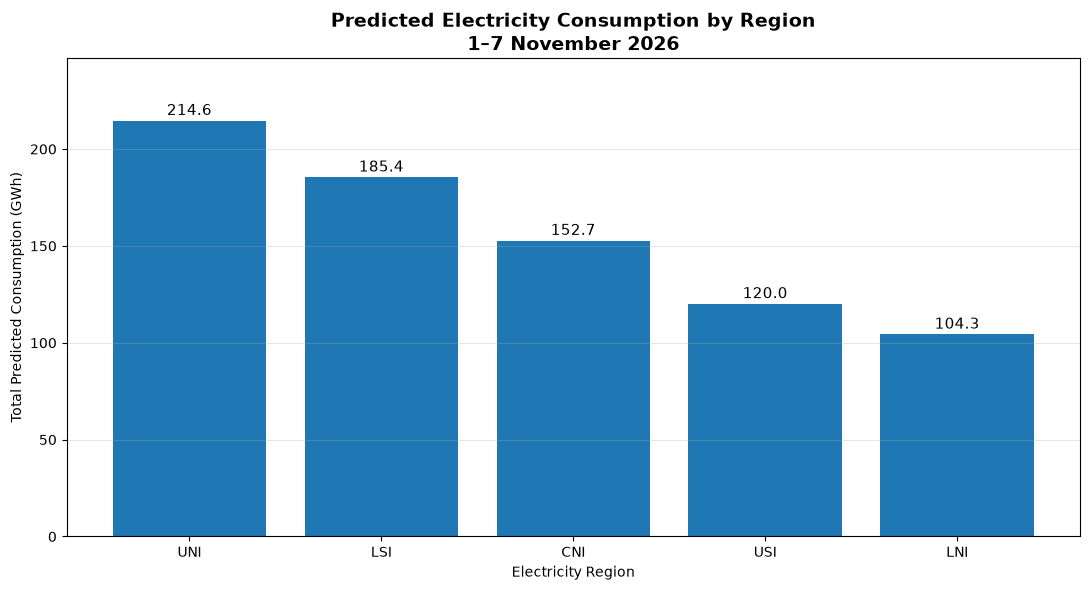

In [10]:
# ============================================================
# REGIONAL ELECTRICITY DEMAND CONTRIBUTIONS
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    demand_summary["Region"],
    demand_summary["Total Demand (GWh)"]
)

# Add values above bars
for bar, value in zip(
    bars,
    demand_summary["Total Demand (GWh)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"{value:.1f}",
        ha="center",
        fontsize=11
    )

ax.set_title(
    "Predicted Electricity Consumption by Region\n"
    "1–7 November 2026",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Electricity Region")
ax.set_ylabel("Total Predicted Consumption (GWh)")

ax.set_ylim(
    0,
    demand_summary["Total Demand (GWh)"].max() * 1.15
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Save chart
plt.savefig(
    figures_dir / "regional_electricity_contributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Final Conclusion — Future Electricity Demand Forecasting

### Project Overview

This notebook demonstrates the application of five trained Random Forest models to generate seven-day electricity demand forecasts for New Zealand.

Each regional model uses historical half-hourly electricity demand observations to predict 336 future periods, representing seven days.

The forecasts cover **1–7 November 2026**.

### Forecast Results

| Region | Predicted Consumption (GWh) | National Share |
|---|---:|---:|
| Upper North Island (UNI) | 214.60 | 27.62% |
| Lower South Island (LSI) | 185.40 | 23.86% |
| Central North Island (CNI) | 152.69 | 19.65% |
| Upper South Island (USI) | 120.05 | 15.45% |
| Lower North Island (LNI) | 104.31 | 13.42% |
| **National Total** | **777.05** | **100%** |

### Key Findings

**1. National electricity consumption**

The models forecast approximately **777.05 GWh (0.777 TWh)** of electricity consumption across New Zealand during the seven-day period.

This corresponds to an average predicted daily consumption of approximately **111.01 GWh**.

**2. Regional electricity demand**

The Upper North Island is forecast to have the highest electricity consumption, accounting for approximately 27.62% of national demand.

The Lower South Island follows with 23.86%, while the Lower North Island accounts for the smallest share at 13.42%.

**3. Daily electricity demand patterns**

The forecasts exhibit recurring daily electricity demand cycles, reflecting changes in consumption throughout the day.

These patterns include higher demand during peak activity periods and lower demand overnight.

**4. Model forecasting performance**

The regional models were evaluated in Notebook 05 using historical test observations.

The combined national forecasts achieved:

- National MAPE: **4.19%**
- Seasonal naïve baseline MAPE: **5.50%**
- Relative MAPE reduction: **23.86%**

These results provide historical evidence of forecasting performance, although they do not guarantee equivalent accuracy for the November forecasts.

### Limitations

- Forecasts rely primarily on historical electricity demand patterns.
- Future weather conditions and unexpected demand changes are not explicitly modelled.
- Regional models operate independently.
- Forecast uncertainty intervals have not been calculated.
- The November predictions have not been validated against actual November electricity consumption.

### Future Development

Potential improvements include:

1. Incorporating weather forecasts and temperature data.
2. Automating daily forecast generation.
3. Developing an interactive electricity demand dashboard.
4. Comparing additional machine-learning algorithms.
5. Introducing prediction intervals to quantify forecast uncertainty.
6. Monitoring model performance as new observations become available.

### Final Conclusion

The forecasting pipeline successfully generated seven-day electricity demand predictions for all five New Zealand electricity regions.

The models forecast a combined national consumption of **777.05 GWh** for 1–7 November 2026.

Historical evaluation demonstrated that the combined regional Random Forest models achieved a national MAPE of **4.19%**, outperforming the seasonal naïve baseline.

This project demonstrates a practical application of machine learning to regional and national electricity demand forecasting.

---

**Project Status:** Completed — Model training, evaluation, future forecasting and visualisation.

**Next Phase:** GitHub documentation, reproducibility and portfolio presentation.